# State of the art: what the literature measured, and what the toolkits leave out

**Question:** What did the published studies on the size and power of these tests conclude, and does the engine, run today, reach the same verdicts?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 02 to 06 of this topic (the measurements the literature is compared with)
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- state what BCBS Working Paper 14, Yurdakul and Naranjo (2020) and Demler, Pencina and D'Agostino (2012) concluded about the size and power of validation tests;
- recompute, with the engine, the critical values the working paper printed for the binomial test and the true size they imply under correlated defaults;
- rerun cells of the PSI study and the nested DeLong study with new seeds and judge them against the published rates;
- decide, verdict by verdict, whether a statement of the literature holds, holds with a qualification or does not hold on the engine;
- say what the validation toolkits document and what they leave unmeasured.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data are the committed artifacts of case C22, validating the validator, drawn with known-truth generators of `riskvalidation.generators` (licence MIT, class `generated`). Three of them carry, under `outputs.golden`, a published simulation study: the rate printed in the paper for each cell, quoted from it. The literature itself is cited from the research dossiers of the product, which read each paper in October 2026; direct quotes are verbatim from those readings.

- **Files read:** `data/derived/C22/clustering.json` (BCBS Working Paper 14, Tables 7 and 8, 144 cells), `drift.json` (Yurdakul and Naranjo, Table 4, 54 cells), `leakage.json` (Demler et al., one cell) and `null.json`.
- **What is taken from them:** the published rates, and the configuration and seed of the rows the engine runs again here.

The next cell loads the four artifacts and prints the engine versions.

In [2]:
# Load the four artifacts of the comparison and print the engine version that baked each
LANG = "en"
ROOT = Path("../../..").resolve()
files = ("clustering", "drift", "leakage", "null")
artifacts = {}
for n in files:
    path = ROOT / "data" / "derived" / "C22" / f"{n}.json"
    artifacts[n] = json.loads(path.read_text(encoding="utf-8"))
rows = {n: {row["key"]: row for row in art["outputs"]["simulations"]} for n, art in artifacts.items()}
clustering, drift, leakage, null = (artifacts[n] for n in files)
for n in files:
    print(f"{n:11s} baked by riskvalidation {artifacts[n]['provenance']['riskvalidation_version']}")
print("installed:", rv.__version__)

clustering  baked by riskvalidation 1.0.1
drift       baked by riskvalidation 1.0.1
leakage     baked by riskvalidation 1.0.1
null        baked by riskvalidation 1.0.1
installed: 1.0.1


## Method

A rerun of a published study is compared with the paper cell by cell. The paper's rate $r_\text{pub}$ comes from $n_\text{pub}$ runs and ours, $\hat r$, from $n$ runs; both estimate one true rate, so their difference has variance $\bar r(1-\bar r)(1/n + 1/n_\text{pub})$ at the pooled rate $\bar r$, and a cell agrees when the standardised difference satisfies $|z| \le 3.29$. The engine's `agrees_with_published` computes it. For each verdict the literature gives about a test, the notebook then runs the engine on that test and says whether the verdict holds, holds with a qualification or does not hold.

## State of the art

### BCBS Working Paper 14 (2005): the calibration tests

The Basel Committee's Working Paper 14 (Studies on the validation of internal rating systems, revised, May 2005) evaluates the calibration tests and runs a simulation study of two of them. Its verdicts (pages 41 to 42):

- **Binomial test:** "Examples in the appendix show that the true type I error (i.e. the probability to reject erroneously the hypothesis of an adequate PD forecast) can be much larger than the nominal level of the test if default events are correlated." Taking dependence into account "yield[s] tests of rather moderate power, even for low levels of correlation".
- **Normal test:** "Simulation studies show that the quality of the normal approximation is moderate but exhibits a conservative bias. As a consequence, the true Type I error tends to be lower than the nominal level of the test".
- **Conclusion:** "at present no really powerful tests of adequate calibration are currently available. Due to the correlation effects that have to be respected there even seems to be no way to develop such tests."

The appendix prints critical values of the binomial test for a PD of 1%, 1,000 obligors and a confidence of 99% (Example 3): 19 defaults when the defaults are independent, and 35, 49, 63 and 77 when the asset correlation is 5%, 10%, 15% and 20% (dossier 12, section 2.2). The first check recomputes them with the engine and the true size they imply.

### Step 1: the binomial test under correlation

`critical_count` finds the smallest default count at which a registered test rejects. With `pd.binomial` at the 1% level it gives the independent critical value, and with `pd.binomial_vasicek` at an assumed correlation it gives the corrected one. `rejection_probability` then returns the true size of the independent test when the defaults follow that correlation. The next cell prints both critical counts and the true size for the correlations of the paper, and draws the size over a grid.

columns: asset correlation, corrected k*, independent k*, true size
0.00   19   19 0.0069
0.05   35   19 0.1113
0.10   49   19 0.1441
0.15   63   19 0.1539
0.20   77   19 0.1549


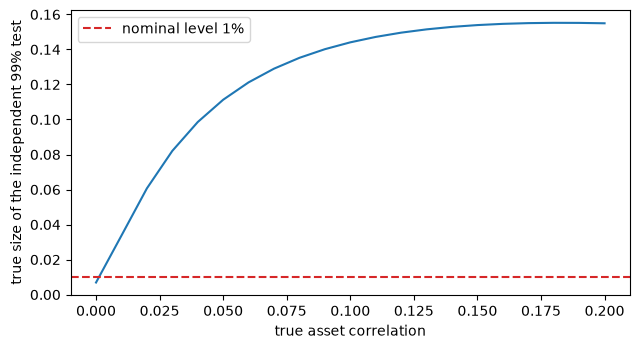

In [3]:
# Critical counts of the independent and the corrected binomial test and the true size of the independent test
from riskvalidation.harness.exact import critical_count, rejection_probability

independent_k = critical_count("pd.binomial", 1000, 0.01, 0.01)
print("columns: asset correlation, corrected k*, independent k*, true size")
size0 = rejection_probability("pd.binomial", 1000, 0.01, 0.01)["probability"]
print(f"{0.0:.2f} {independent_k:4d} {independent_k:4d} {size0:.4f}")
for rho in (0.05, 0.10, 0.15, 0.20):
    corrected_k = critical_count("pd.binomial_vasicek", 1000, 0.01, 0.01, rho=rho)
    size = rejection_probability("pd.binomial", 1000, 0.01, 0.01, rho_true=rho)["probability"]
    print(f"{rho:.2f} {corrected_k:4d} {independent_k:4d} {size:.4f}")
grid = np.linspace(0.0, 0.2, 21)
curve = [rejection_probability("pd.binomial", 1000, 0.01, 0.01, rho_true=r)["probability"] for r in grid]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(grid, curve)
ax.axhline(0.01, color="tab:red", linestyle="--", label="nominal level 1%")
ax.set_xlabel("true asset correlation")
ax.set_ylabel("true size of the independent 99% test")
ax.legend()
fig.tight_layout()
plt.show()

The engine returns the critical values of the paper's example: 19 defaults for independent defaults and 35, 49, 63 and 77 for asset correlations of 5%, 10%, 15% and 20%. The independent test, with its threshold of 19, has a true size of 0.0069 when the defaults are independent and 0.1113 at 5%, 0.1441 at 10%, 0.1539 at 15% and 0.1549 at 20%, against a nominal 1%. The working paper's verdict on the binomial test, that its true type I error can be much larger than the nominal one under correlation, holds exactly: the size is more than ten times the level.

### Step 2: the verdict on the normal test

The paper says the normal test "exhibits a conservative bias", with a true type I error that "tends to be lower than the nominal level". Its own Table 7 reports the type I error at 5% in eight scenarios, four with independent years (`I_`) and four with dependence (`DC_`, `DV_`). The next cell reads those published rates and counts how many exceed 5% in each group, then simulates the normal test along the clustering ladder with the engine, 1,000 repetitions per rung, and draws the published rates beside the measured sizes.

independent years      published rates at 5%: [0.059, 0.059, 0.077, 0.081]
                       above 5%: 4 of 4
dependent years        published rates at 5%: [0.037, 0.049, 0.062, 0.07]
                       above 5%: 2 of 4
size of the normal test along the ladder: [0.083, 0.091, 0.077, 0.056, 0.034, 0.039]


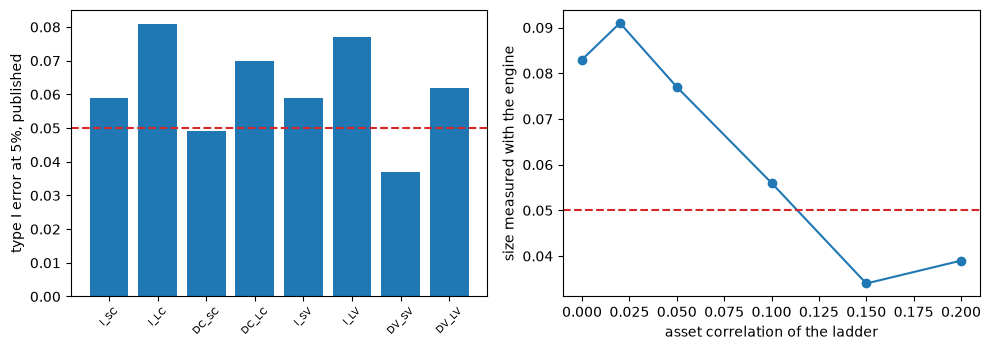

In [4]:
# Read the published type I errors of the normal test and measure its size along the clustering ladder
from riskvalidation.generators.counts import DefaultCounts, feed_series
from riskvalidation.harness.run import simulate

study = clustering["outputs"]["golden"][0]
published = {c["row"]: c["published"] for c in study["cells"] if c["table"] == "Table 7" and c["column"] == "0.05"}
normal = {name: rate for name, rate in published.items() if "normal" in name}
for group, prefix in (("independent years", "I_"), ("dependent years", "D")):
    chosen = [rate for name, rate in normal.items() if name.startswith(prefix)]
    print(f"{group:22s} published rates at 5%: {sorted(chosen)}")
    print(f"{'':22s} above 5%: {sum(r > 0.05 for r in chosen)} of {len(chosen)}")
ladder = clustering["outputs"]["ladder"]["values"]
measured = []
for rho in ladder:
    row = rows["clustering"][f"pd.normal_multiperiod@rho{rho:g}"]
    generator = DefaultCounts(**clustering["outputs"]["generators"][row["generator"]]["config"])
    run = simulate(row["test_id"], generator, n_rep=1000, seed=row["seed"], feed=feed_series())
    measured.append(run.rates["p<0.05"].rate)
print("size of the normal test along the ladder:", [round(m, 4) for m in measured])
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(range(len(normal)), list(normal.values()), color="tab:blue")
left.axhline(0.05, color="tab:red", linestyle="--")
left.set_xticks(range(len(normal)))
left.set_xticklabels([name.split(",")[0] for name in normal], rotation=45, fontsize=7)
left.set_ylabel("type I error at 5%, published")
right.plot(ladder, measured, "o-")
right.axhline(0.05, color="tab:red", linestyle="--")
right.set_xlabel("asset correlation of the ladder")
right.set_ylabel("size measured with the engine")
fig.tight_layout()
plt.show()

The verdict holds only with a qualification. For independent years all four published rates are above 5%, between 0.059 and 0.081, so the test is not conservative there; for dependent years two of the four are above, between 0.037 and 0.070. The engine's own sizes along the ladder run from 0.083 with independent defaults down to 0.034 at an asset correlation of 15% and 0.039 at 20%: the test over-rejects when the years are independent and under-rejects when they are strongly dependent, and the paper's word conservative describes only the second case.

### Step 3: "no really powerful tests"

The paper concludes that no really powerful calibration test is available under correlated defaults. The Vasicek-corrected binomial test is its own answer to correlation, and its exact power can be computed when the true correlation equals the assumed one. The next cell computes the power at 5% for 1,000 obligors at a PD of 1% as the true PD rises to 1.25, 1.5, 2 and 3 times the PD applied, for asset correlations of 5% and 12%, and prints the uncorrected test beside it. At $k = 1$ the figure is the size, which tells whether the power is bought with false alarms.

asset correlation 0.05 | corrected: [0.043, 0.087, 0.145, 0.284, 0.561]
asset correlation 0.05 | uncorrected: [0.178, 0.282, 0.388, 0.576, 0.816]
asset correlation 0.12 | corrected: [0.05, 0.08, 0.114, 0.19, 0.349]
asset correlation 0.12 | uncorrected: [0.198, 0.27, 0.34, 0.465, 0.653]


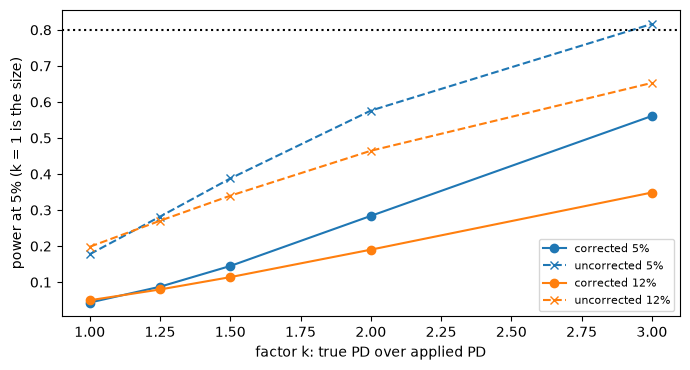

In [5]:
# Exact power of the corrected and the uncorrected binomial test under correlated defaults, n = 1000, PD = 1%
factors = np.array([1.0, 1.25, 1.5, 2.0, 3.0])
fig, ax = plt.subplots(figsize=(7, 3.8))
for index, rho in enumerate((0.05, 0.12)):
    corrected, plain = [], []
    for k in factors:
        kw = {"pd_true": 0.01 * k, "rho_true": rho}
        corrected.append(rejection_probability("pd.binomial_vasicek", 1000, 0.01, 0.05, rho=rho, **kw)["probability"])
        plain.append(rejection_probability("pd.binomial", 1000, 0.01, 0.05, **kw)["probability"])
    print(f"asset correlation {rho:.2f} | corrected:", [round(p, 3) for p in corrected])
    print(f"asset correlation {rho:.2f} | uncorrected:", [round(p, 3) for p in plain])
    ax.plot(factors, corrected, "o-", color=f"C{index}", label=f"corrected {rho:.0%}")
    ax.plot(factors, plain, "x--", color=f"C{index}", label=f"uncorrected {rho:.0%}")
ax.axhline(0.8, color="black", linestyle=":")
ax.set_xlabel("factor k: true PD over applied PD")
ax.set_ylabel("power at 5% (k = 1 is the size)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

With an asset correlation of 5% the corrected test has a size of 0.043 and its power is 0.087, 0.145, 0.284 and 0.561 for $k$ = 1.25, 1.5, 2 and 3; with 12% it is 0.050 at $k = 1$ and 0.349 at $k = 3$. These are modest figures: a PD three times too low goes unnoticed one time in two at 5% and two times in three at 12%. The uncorrected test is much more powerful, 0.816 and 0.653 at $k = 3$, but at $k = 1$ it rejects 0.178 and 0.198 of right models. The verdict holds with a qualification: tests with an honest size are weak, and the powerful ones are not honest.

### Yurdakul and Naranjo (2020): the PSI

Yurdakul and Naranjo (Statistical properties of the population stability index, Journal of Risk Model Validation 14(4)) start from the observation that the PSI bands of 0.10 and 0.25 are "used without reference to statistical type I or type II error rates". They derive the sampling distribution of the index (their Theorem 3.3), propose the benchmark $(1/n + 1/m)\,\chi^2_{1-\alpha,\,B-1}$ and report a simulation (Table 4) with 10,000 runs. Their reading: "the type I error rate for PSI > 0.10 is too large, except when both sample sizes exceed 400. In contrast, the type I error rate for PSI > 0.25 is too small when both sample sizes exceed 200, so the test is too conservative. The chi-square benchmark maintains a reasonable type I error, close to $\alpha$ = 0.05 [...] the tests PSI > 0.10 and PSI > 0.25 have powers that actually decrease with sample size."


### Step 4: the PSI study, rerun

Yurdakul and Naranjo ran 10,000 runs per cell of their Table 4. The next cell reruns the equal-sample cells, sizes 100, 200 and 400 with shifts of 0, a quarter and a half standard deviation, for the two rules of thumb and the chi-square benchmark, 27 cells with 2,000 repetitions and a new seed, tests each against the published rate with `agrees_with_published` and draws the rerun rates against the published ones.

cells rerun: 27 | that agree with the paper: 27


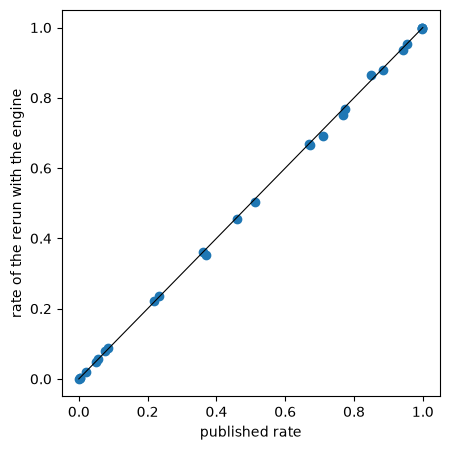

In [6]:
# Rerun cells of Table 4 with equal samples and plot them against the published ones
from riskvalidation.generators.drift import TwoSample
from riskvalidation.harness.rates import agrees_with_published
from riskvalidation.harness.run import metric_above

rules = (metric_above(0.10, "metric>0.1"), metric_above(0.25, "metric>0.25"))
table4 = {(c["row"], c["column"]): c["published"] for c in drift["outputs"]["golden"][0]["cells"]}
columns = (("metric>0.1", "PSI > 0.10"), ("metric>0.25", "PSI > 0.25"), ("p<0.05", "chi-square"))
pairs, agree = [], 0
for size in (100, 200, 400):
    for shift in (0, 0.25, 0.5):
        run = simulate("stability.psi", TwoSample(size, size, shift=shift), n_rep=2000, seed=7, rules=rules)
        for rule, column in columns:
            pub = table4[(f"m {size}, n {size}", f"shift {shift:g} SD, {column}")]
            ok, z = agrees_with_published(run.rates[rule], pub, drift["outputs"]["golden"][0]["runs_published"])
            agree += ok
            pairs.append((pub, run.rates[rule].rate))
print("cells rerun:", len(pairs), "| that agree with the paper:", agree)
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.plot([p[0] for p in pairs], [p[1] for p in pairs], "o")
ax.plot([0, 1], [0, 1], color="black", linewidth=0.8)
ax.set_xlabel("published rate")
ax.set_ylabel("rate of the rerun with the engine")
fig.tight_layout()
plt.show()

All 27 cells agree with the paper, and the points lie on the diagonal over the whole range from 0 to 1. The rerun therefore supports the paper's reading of its own table: the 0.10 rule has a type I error far above 5% for small samples, the 0.25 rule is too conservative for samples above 200, and the chi-square benchmark stays close to the 5% level. The qualitative findings hold for the engine, which is the point of rerunning them with a seed that the paper never used.

### Demler, Pencina and D'Agostino (2012): DeLong on nested models

Demler et al. (Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23)) show that the DeLong test, derived for models with known parameters, is conservative when it compares two models fitted on the same data and the larger one adds a predictor with no effect. Their simulation, on Framingham-like data with 1,000 repetitions, found: "the significance level for the F-test is close to the nominal 0.05 level, whereas it is 0.001 for the DeLong test."


### Step 5: DeLong on nested models

The file holds the one published cell, 0.001, and the design of the study: a pair of nested linear discriminant models on Framingham-like data, 1,000 repetitions. The next cell reruns it with `NestedLda` and `simulate`, tests the rate against the published one, and runs the same DeLong test on a non-nested pair of scores on an independent sample, where the paper finds no problem. A bar chart sets the three rates against the nominal 5%.

published rate (Demler et al.): 0.001 | nested, engine: 0.002
z: 0.58 | agrees: True | non-nested, engine: 0.0525


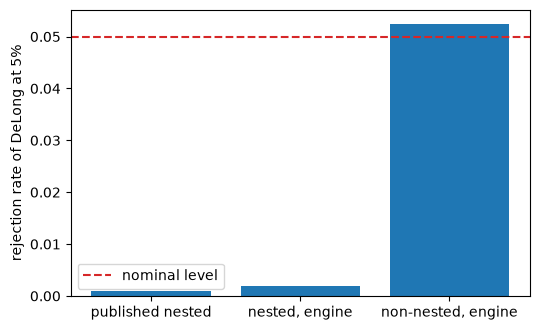

In [7]:
# Rerun the nested DeLong comparison and compare it with the published rate and with a non-nested comparison
from riskvalidation.generators.framingham import NestedLda
from riskvalidation.generators.scores import BinormalScores

cell = leakage["outputs"]["golden"][0]["cells"][0]
nested = rows["leakage"]["disc.delong@nested"]
nested_gen = NestedLda(**leakage["outputs"]["generators"][nested["generator"]]["config"])
run = simulate("disc.delong", nested_gen, n_rep=nested["n_rep"], seed=nested["seed"])
ok, z = agrees_with_published(run.rates["p<0.05"], cell["published"], leakage["outputs"]["golden"][0]["runs_published"])
other = rows["leakage"]["disc.delong@non-nested"]
pair = BinormalScores(**leakage["outputs"]["generators"][other["generator"]]["config"])
rate_other = simulate("disc.delong", pair, n_rep=other["n_rep"], seed=other["seed"]).rates["p<0.05"]
print("published rate (Demler et al.):", cell["published"], "| nested, engine:", run.rates["p<0.05"].rate)
print("z:", round(z, 2), "| agrees:", ok, "| non-nested, engine:", round(rate_other.rate, 4))
fig, ax = plt.subplots(figsize=(5.5, 3.4))
labels = ["published nested", "nested, engine", "non-nested, engine"]
ax.bar(labels, [cell["published"], run.rates["p<0.05"].rate, rate_other.rate])
ax.axhline(0.05, color="tab:red", linestyle="--", label="nominal level")
ax.set_ylabel("rejection rate of DeLong at 5%")
ax.legend()
fig.tight_layout()
plt.show()

The engine rejects 0.002 of the nested comparisons against the 0.001 published, a standardised difference of 0.58, so the cell agrees, and the test is as conservative as the paper says: it rejects a right comparison one time in five hundred instead of one in twenty. On a non-nested pair the same test rejects 0.0525, at its level. The defect belongs to the use of the test on nested models fitted on the same sample, and a validator who applies DeLong to a champion and a challenger that share predictors loses almost all of its power without being told.

### The ECB tests and the validation toolkits

The ECB's instructions for reporting validation results (2019) define the statistics and the p-values of the tests the engine implements (the Jeffreys test, the AUC against the initial AUC, the migration tests, the concentration test). The product's research (dossier 06, section A.3) verified by full-text search that the document fixes statistics and p-values and sets no pass or fail thresholds, which are the institution's responsibility.

The toolkits the research surveyed on 2026-10-04 (dossier 06, section D, through the GitHub and PyPI interfaces) offer, among others:

| Toolkit | What its documentation lists | Licence |
|---|---|---|
| PiML-Toolbox | outcome tests: accuracy, explainability, fairness, weak spots, overfit, reliability, robustness, resilience; superseded by MoDeVa | Apache-2.0 (MoDeVa proprietary) |
| ValidMind | data and model validation tests, including PSI, KS, Gini and calibration curves, and drift | AGPL-3.0 or commercial |
| BBVA mercury-robust and mercury-monitoring | drift, label leaking, schema and cohort tests | Apache-2.0 |
| ING popmon | drift: KS, chi-squared, Jensen-Shannon, PSI; traffic lights on pulls of 4 and 7 standard deviations | MIT |
| Evidently | drift: KS, chi-squared, z-test, Wasserstein, Jensen-Shannon, PSI, KL; data quality; model quality | Apache-2.0 |
| NannyML | label-free performance estimation, univariate and multivariate drift | Apache-2.0 |
| deepchecks | data integrity, train-test validation and model evaluation suites | AGPL-3.0 |
| alibi-detect | drift: KS, MMD, LSDD, chi-square, classifier-based; outliers | BSL 1.1 |

The dossier records (lines 1117 to 1121) that no toolkit found implements the ECB Jeffreys, MWB, migration z-tests, HHI-CV test or gAUC exactly as specified. Its catalogues list tests, thresholds and traffic lights; the dossier recorded no measured size or power for them in the READMEs and documentation it read. That is a statement about what the survey found, and UNVERIFIED beyond it: the survey did not run the toolkits or read their source.

## Results

**Answer:** The engine reproduces the published studies it was asked to rerun: the working paper's critical values come out as 19, 35, 49, 63 and 77 defaults, all 27 rerun cells of the PSI study agree, and the nested DeLong rate is 0.002 against 0.001 published. Its verdicts split. The one on the binomial test holds exactly, with a true size of 0.1113 at an asset correlation of 5% against a nominal 1%. The one on the normal test holds only for dependent years: its published rates for independent years are all above 5%, between 0.059 and 0.081. The conclusion that no powerful test exists holds with a qualification: the corrected test has a power of 0.561 at $k = 3$ and the powerful uncorrected one has a size of 0.178.

- **The toolkits document tests, not error rates.** The survey of toolkits found catalogues of tests, thresholds and traffic lights, and no measured size or power; that is a statement about the documentation read, UNVERIFIED beyond it.
- **The literature measured few tests.** Three studies cover two calibration tests, the PSI rules and one DeLong design, each on its own assumptions.
- **A rerun with a new seed is evidence.** It does not depend on the committed counts: the 27 PSI cells and the nested DeLong cell were drawn here.

Measuring every test under one protocol is the claim of the next notebook.

## Summary

- Three published studies measured the size or power of validation tests, each on one design: BCBS Working Paper 14, Yurdakul and Naranjo, and Demler et al.
- The engine reproduces their numbers: the critical values 19, 35, 49, 63 and 77, 27 of 27 rerun PSI cells, and the nested DeLong cell.
- The verdict on the binomial test holds exactly; the one on the normal test holds only when the years are dependent; the one on power holds with a qualification.
- DeLong's test is conservative on nested models and at its level on non-nested ones.
- The toolkits surveyed document tests, thresholds and traffic lights, and no measured error rates.

**What to try next.** Rerun step 3 with an asset correlation of 20% and compare the powers, then read notebook 08.

## References

- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the verdicts on the calibration tests (pages 41 to 42), the appendix examples on the binomial test, and the simulation of the normal and traffic-lights tests (pages 61 to 67). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Demler, O. V., Pencina, M. J. and D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- The product's research dossiers (CAOS_MANAGE records, `wip/contraste/`): 06 (model risk management and validation, sections A, C and D) and 12 (size, power and generators, sections 1 to 6), read on 2026-10-04 and 2026-10-05; and this repository's `docs/design/features/c22-validator/requirements.md`.